### Lung cancer

In [ ]:
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import pandas as pd
import os
from sklearn.model_selection import StratifiedGroupKFold

##### Fsocre

In [6]:
# 加载数据集
file_path = '../Fscore/Lung_sample_FscoreSorted_selected60.csv'
Fscoredata = pd.read_csv(file_path)

# 数据存储目录
output_dir = "../all_biomaker_detection/"
os.makedirs(output_dir, exist_ok=True)

In [ ]:
# 准备训练和测试集函数
def prepare_train_test_Fscore(data, cancer_type, output_dir):
    
    # 分层采样：拆分训练集和测试集，确保类别比例一致
    sgkf = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    train_idx, test_idx = next(
        sgkf.split(
            data,
            y=data["class"],
            groups=data["SampleID"]
        )
    )

    train_data = data.iloc[train_idx]
    test_data = data.iloc[test_idx]

    train_data = train_data.drop(columns=["SampleID"])
    test_data = test_data.drop(columns=["SampleID"])

    # 设置模型保存路径
    model_path = os.path.join(output_dir, f"Model_{cancer_type}/Fscore/")
    os.makedirs(model_path, exist_ok=True)

    # 训练 AutoGluon 模型
    predictor = TabularPredictor(label='class', eval_metric='roc_auc', path=model_path).fit(
        train_data=train_data,
        presets='best_quality',
        hyperparameters={'XGB': {}, 'RF': {'criterion': 'gini'}, 'GBM': {}, 'FASTAI': {}, 'ENS_WEIGHTED': {}},
        # num_bag_folds=5
    )

    # predictor=TabularPredictor.load(f".\pancancer_detection\Model_{cancer_type}/")

    # 查看模型排行榜
    leaderboard = predictor.leaderboard(test_data, extra_metrics=['accuracy', 'balanced_accuracy', 'mcc', 'f1', 'precision', 'recall', 'roc_auc'])
    return leaderboard

In [6]:
Lung_leaderboard_Fscore = prepare_train_test_Fscore(Fscoredata, "Lung cancer", output_dir)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.1.1
Python Version:     3.12.9
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #53~22.04.1-Ubuntu SMP PREEMPT_DYNAMIC Wed Jan 15 19:18:46 UTC 2
CPU Count:          48
Memory Avail:       187.67 GB / 251.54 GB (74.6%)
Disk Space Avail:   8944.01 GB / 14784.53 GB (60.5%)
Presets specified: ['best_quality']
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1
DyStack is enabled (dynamic_stacking=True). AutoGluon will try to determine whether the input data is affected by stacked overfitting and enable or disable stacking as a consequence.
	This is used to identify the optimal `num_stack_levels` value. Copies of AutoGluon will be fit on subsets of the data. Then holdout validation data is u

(_ray_fit pid=4096264) [1000]	valid_set's binary_logloss: 0.0282337


(_dystack pid=4092800) 	0.9722	 = Validation score   (roc_auc)
(_dystack pid=4092800) 	0.66s	 = Training   runtime
(_dystack pid=4092800) 	0.01s	 = Validation runtime
(_dystack pid=4092800) Fitting model: RandomForest_BAG_L1 ... Training model for up to 594.88s of the 893.65s of remaining time.
(_dystack pid=4092800) 	0.9719	 = Validation score   (roc_auc)
(_dystack pid=4092800) 	1.71s	 = Training   runtime
(_dystack pid=4092800) 	0.1s	 = Validation runtime
(_dystack pid=4092800) Fitting model: NeuralNetFastAI_BAG_L1 ... Training model for up to 593.02s of the 891.79s of remaining time.
(_dystack pid=4092800) 	Fitting 8 child models (S1F1 - S1F8) | Fitting with ParallelLocalFoldFittingStrategy (8 workers, per: cpus=6, gpus=0, memory=0.00%)
(_dystack pid=4092800) 	0.9669	 = Validation score   (roc_auc)
(_dystack pid=4092800) 	6.32s	 = Training   runtime
(_dystack pid=4092800) 	0.1s	 = Validation runtime
(_dystack pid=4092800) Fitting model: XGBoost_BAG_L1 ... Training model for up to 58

In [7]:
Lung_leaderboard_Fscore.to_csv("Lung_leaderboard_Fscore.csv", index=False)
Lung_leaderboard_Fscore

,model,score_test,accuracy,balanced_accuracy,mcc,f1,precision,recall,roc_auc,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,NeuralNetFastAI_BAG_L2,0.968687,0.908257,0.907744,0.821316,0.901961,0.958333,0.851852,0.968687,0.977043,roc_auc,3.141037,0.533963,16.570955,0.736553,0.148382,7.129231,2,True,8
1,NeuralNetFastAI_BAG_L1,0.963973,0.871560,0.870707,0.755538,0.857143,0.954545,0.777778,0.963973,0.966685,roc_auc,1.802865,0.194062,6.229442,1.802865,0.194062,6.229442,1,True,3
2,WeightedEnsemble_L2,0.961616,0.899083,0.898653,0.801364,0.893204,0.938776,0.851852,0.961616,0.982539,roc_auc,2.103402,0.340420,8.314905,0.002268,0.000502,0.027148,2,True,5
3,RandomForest_BAG_L1,0.960943,0.908257,0.907744,0.821316,0.901961,0.958333,0.851852,0.960943,0.978216,roc_auc,0.053260,0.108979,1.348955,0.053260,0.108979,1.348955,1,True,2
4,WeightedEnsemble_BAG_L2,0.960606,0.908257,0.908081,0.816987,0.905660,0.923077,0.888889,0.960606,0.981229,roc_auc,2.410615,0.392699,9.568503,0.006131,0.007118,0.126779,2,True,10
5,WeightedEnsemble_L3,0.958923,0.908257,0.907744,0.821316,0.901961,0.958333,0.851852,0.958923,0.983829,roc_auc,3.562714,0.608034,18.345739,0.002122,0.000469,0.080570,3,True,11
6,RandomForest_BAG_L2,0.953872,0.880734,0.880135,0.767540,0.871287,0.936170,0.814815,0.953872,0.978639,roc_auc,2.452815,0.495878,10.677990,0.048331,0.110297,1.236266,2,True,7
7,LightGBM_BAG_L2,0.952525,0.899083,0.898653,0.801364,0.893204,0.938776,0.851852,0.952525,0.979770,roc_auc,2.541006,0.395923,10.239958,0.136523,0.010342,0.798234,2,True,6
8,LightGBM_BAG_L1,0.950842,0.889908,0.889562,0.781761,0.884615,0.920000,0.851852,0.950842,0.979072,roc_auc,0.245009,0.036877,0.709360,0.245009,0.036877,0.709360,1,True,1
9,XGBoost_BAG_L1,0.949832,0.880734,0.880471,0.762485,0.876190,0.901961,0.851852,0.949832,0.977128,roc_auc,0.303350,0.045663,1.153967,0.303350,0.045663,1.153967,1,True,4


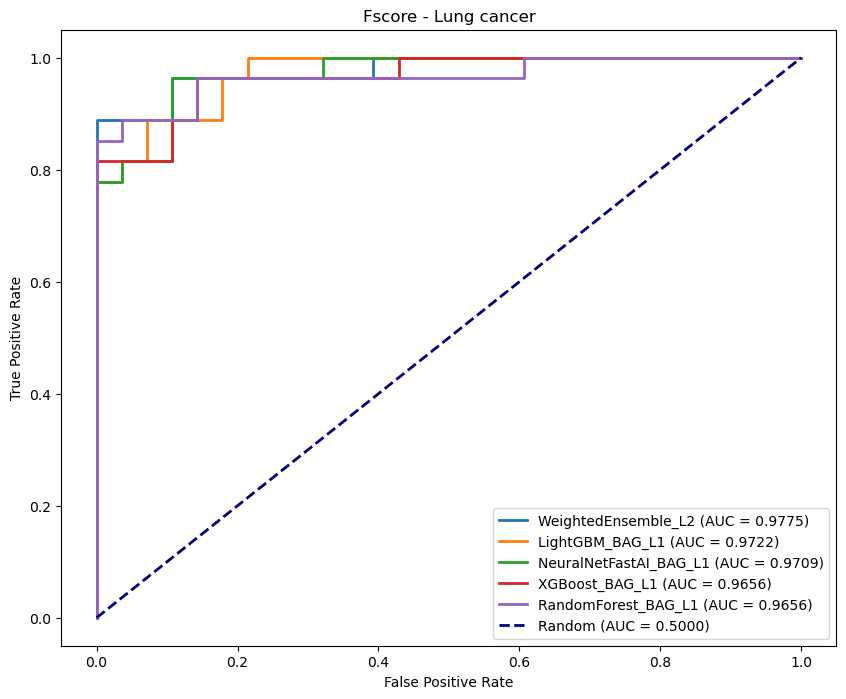

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split

def plot_roc_curves_Fscore(data, model_dir):
    # 加载模型
    predictor = TabularPredictor.load(model_dir)
    models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 
              'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']
    
    # 拆分数据集
    train_data, temp_data = train_test_split(data, test_size=0.2, random_state=42, stratify=data['class'])
    val_data, test_data = train_test_split(temp_data, test_size=0.5, random_state=42, stratify=temp_data['class'])
    y_true = test_data['class']
    
    # 收集各模型及Random的ROC数据
    roc_entries = []
    for model_name in models:
        model = predictor._trainer.load_model(model_name)
        y_prob = model.predict_proba(test_data)
        fpr, tpr, _ = roc_curve(y_true, y_prob)
        roc_auc = auc(fpr, tpr)
        roc_entries.append((model_name, fpr, tpr, roc_auc))
    
    # 添加Random的ROC数据
    roc_entries.append(('Random', [0, 1], [0, 1], 0.5))
    
    # 按AUC降序排序
    roc_entries.sort(key=lambda x: x[3], reverse=True)
    
    # 绘制曲线
    plt.figure(figsize=(10, 8))
    for entry in roc_entries:
        name, fpr, tpr, auc_val = entry
        if name == 'Random':
            plt.plot(fpr, tpr, '--', color='navy', lw=2, 
                     label=f'{name} (AUC = {auc_val:.4f})')
        else:
            plt.plot(fpr, tpr, lw=2, 
                     label=f'{name} (AUC = {auc_val:.4f})')
    
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Fscore - Lung cancer')
    plt.legend(loc='lower right')

    plt.savefig(f"{model_dir}", dpi=300)
    plt.show()

model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Lung cancer/Fscore'
data = Fscoredata 
plot_roc_curves_Fscore(data, model_dir)


##### ANOVA

In [6]:
# 加载数据集
file_path = '../ANOVA/Lung_sample_AnovaSorted_selected60.csv'
ANOVAdata = pd.read_csv(file_path)

# 数据存储目录
output_dir = "../all_biomaker_detection/"
os.makedirs(output_dir, exist_ok=True)

In [ ]:
# 准备训练和测试集函数
def prepare_train_test_ANOVA(data, cancer_type, output_dir):

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    sgkf = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    train_idx, test_idx = next(
        sgkf.split(
            data,
            y=data["class"],
            groups=data["SampleID"]
        )
    )

    train_data = data.iloc[train_idx]
    test_data = data.iloc[test_idx]

    train_data = train_data.drop(columns=["SampleID"])
    test_data = test_data.drop(columns=["SampleID"])

    # 设置模型保存路径
    model_path = os.path.join(output_dir, f"Model_{cancer_type}/ANOVA/")
    os.makedirs(model_path, exist_ok=True)

    # 训练 AutoGluon 模型
    predictor = TabularPredictor(label='class', eval_metric='roc_auc', path=model_path).fit(
        train_data=train_data,
        presets='best_quality',
        hyperparameters={'XGB': {}, 'RF': {'criterion': 'gini'}, 'GBM': {}, 'FASTAI': {}, 'ENS_WEIGHTED': {}},
        # num_bag_folds=5
    )

    # predictor=TabularPredictor.load(f".\pancancer_detection\Model_{cancer_type}/")

    # 查看模型排行榜
    leaderboard = predictor.leaderboard(test_data, extra_metrics=['accuracy', 'balanced_accuracy', 'mcc', 'f1', 'precision', 'recall', 'roc_auc'])
    return leaderboard

In [11]:
Lung_leaderboard_ANOVA = prepare_train_test_ANOVA(ANOVAdata, "Lung cancer", output_dir)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.1.1
Python Version:     3.12.9
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #53~22.04.1-Ubuntu SMP PREEMPT_DYNAMIC Wed Jan 15 19:18:46 UTC 2
CPU Count:          48
Memory Avail:       186.62 GB / 251.54 GB (74.2%)
Disk Space Avail:   8943.99 GB / 14784.53 GB (60.5%)
Presets specified: ['best_quality']
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1
DyStack is enabled (dynamic_stacking=True). AutoGluon will try to determine whether the input data is affected by stacked overfitting and enable or disable stacking as a consequence.
	This is used to identify the optimal `num_stack_levels` value. Copies of AutoGluon will be fit on subsets of the data. Then holdout validation data is u

Leaderboard on holdout data (DyStack):
                      model  score_holdout  score_val eval_metric  pred_time_test  pred_time_val   fit_time  pred_time_test_marginal  pred_time_val_marginal  fit_time_marginal  stack_level  can_infer  fit_order
0            XGBoost_BAG_L1       0.976667   0.968617     roc_auc        0.275265       0.031852   1.334195                 0.275265                0.031852           1.334195            1       True          4
1    NeuralNetFastAI_BAG_L2       0.975000   0.974013     roc_auc        4.410815       0.543897  20.354509                 1.165922                0.179667           7.127883            2       True          8
2       RandomForest_BAG_L1       0.973333   0.971932     roc_auc        0.038825       0.103881   1.790159                 0.038825                0.103881           1.790159            1       True          2
3           LightGBM_BAG_L2       0.973333   0.970201     roc_auc        3.378764       0.373255  13.867183          

In [12]:
Lung_leaderboard_ANOVA.to_csv("Lung_leaderboard_ANOVA.csv", index=False)
Lung_leaderboard_ANOVA

,model,score_test,accuracy,balanced_accuracy,mcc,f1,precision,recall,roc_auc,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,NeuralNetFastAI_BAG_L2,0.968687,0.908257,0.907744,0.821316,0.901961,0.958333,0.851852,0.968687,0.977043,roc_auc,1.809460,0.423080,16.939160,0.655729,0.130768,7.050057,2,True,8
1,NeuralNetFastAI_BAG_L1,0.963973,0.871560,0.870707,0.755538,0.857143,0.954545,0.777778,0.963973,0.966685,roc_auc,0.683517,0.160055,6.860107,0.683517,0.160055,6.860107,1,True,3
2,WeightedEnsemble_L2,0.961616,0.899083,0.898653,0.801364,0.893204,0.938776,0.851852,0.961616,0.982539,roc_auc,0.888114,0.262436,8.922550,0.002196,0.000482,0.025548,2,True,5
3,RandomForest_BAG_L1,0.960943,0.908257,0.907744,0.821316,0.901961,0.958333,0.851852,0.960943,0.978216,roc_auc,0.061017,0.091855,1.282666,0.061017,0.091855,1.282666,1,True,2
4,WeightedEnsemble_L3,0.958923,0.908257,0.907744,0.821316,0.901961,0.958333,0.851852,0.958923,0.983829,roc_auc,2.238491,0.492826,18.571446,0.002517,0.000458,0.065893,3,True,11
5,WeightedEnsemble_BAG_L2,0.958923,0.889908,0.889226,0.788062,0.880000,0.956522,0.814815,0.958923,0.981229,roc_auc,1.159744,0.299479,10.024625,0.006012,0.007167,0.135522,2,True,10
6,RandomForest_BAG_L2,0.953872,0.880734,0.880135,0.767540,0.871287,0.936170,0.814815,0.953872,0.978639,roc_auc,1.205818,0.395021,11.194336,0.052087,0.102709,1.305233,2,True,7
7,LightGBM_BAG_L2,0.952525,0.899083,0.898653,0.801364,0.893204,0.938776,0.851852,0.952525,0.979770,roc_auc,1.307196,0.302553,10.643043,0.153465,0.010241,0.753940,2,True,6
8,LightGBM_BAG_L1,0.950842,0.889908,0.889562,0.781761,0.884615,0.920000,0.851852,0.950842,0.979072,roc_auc,0.141384,0.010044,0.754229,0.141384,0.010044,0.754229,1,True,1
9,XGBoost_BAG_L1,0.949832,0.880734,0.880471,0.762485,0.876190,0.901961,0.851852,0.949832,0.977128,roc_auc,0.267813,0.030358,0.992101,0.267813,0.030358,0.992101,1,True,4


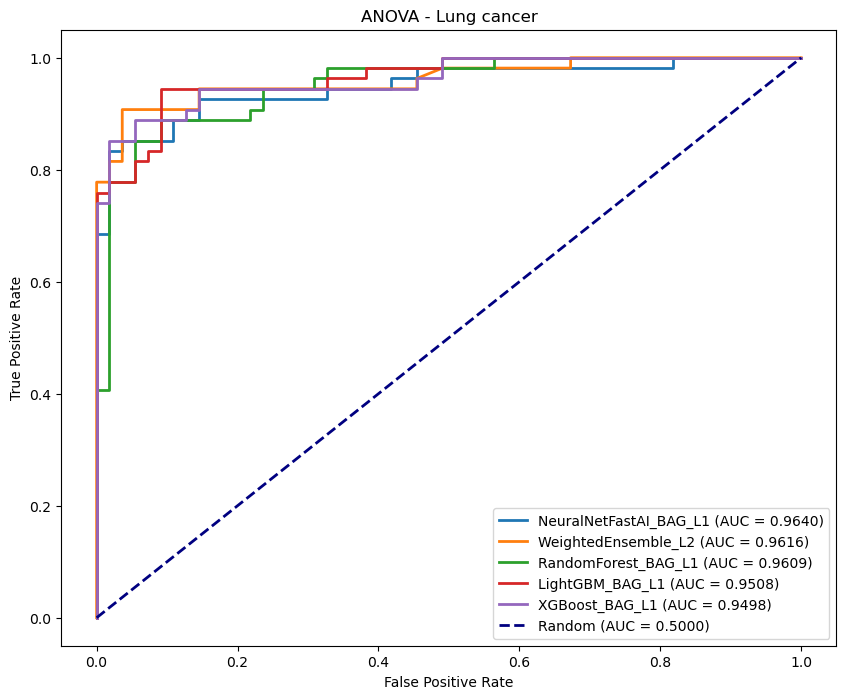

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split

# 加载模型并绘制 ROC 曲线
def plot_roc_curves_ANOVA(data, model_dir):
    # 加载整个 predictor 对象
    ANOVA_predictor = TabularPredictor.load(model_dir)

    # 定义你想加载的模型名称
    models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']
    
    # 用于存储每个模型和对应的 AUC 值
    auc_scores = []
    
    plt.figure(figsize=(10, 8))

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    train_data, test_data = train_test_split(
        data, test_size=0.2, random_state=42, stratify=data['class']
    )

    y_true = test_data['class']  # 真实标签
    
    for model_name in models:
        # 加载每个模型
        model = ANOVA_predictor._trainer.load_model(model_name)

        # 获取模型的预测概率
        y_prob = model.predict_proba(test_data)  # 获取每个样本的预测概率（正类的概率）

        # 计算 ROC 曲线的数据
        fpr, tpr, thresholds = roc_curve(y_true, y_prob)  # 只取正类概率
        roc_auc = auc(fpr, tpr)

        # 将模型和 AUC 值存储到列表中
        auc_scores.append((model_name, roc_auc))

        # 绘制 ROC 曲线
        plt.plot(fpr, tpr, lw=2, label=f'{model_name} (AUC = {roc_auc:.4f})')

    # 按照 AUC 值从大到小排序
    auc_scores.append(('Random', 0.5))
    auc_scores.sort(key=lambda x: x[1], reverse=True)

    # 绘制随机猜测线
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label="Random (AUC = 0.5)")

    # 配置图表
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ANOVA - Lung cancer')

    # 使用排序后的 AUC 值生成图例
    sorted_labels = [f'{model_name} (AUC = {roc_auc:.4f})' for model_name, roc_auc in auc_scores]
    plt.legend(sorted_labels, loc='lower right')

    plt.savefig(f"{model_dir}", dpi=300)
    plt.show()

model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Lung cancer/ANOVA'
data = ANOVAdata 
plot_roc_curves_ANOVA(data, model_dir)


##### ReliefF

In [3]:
# 加载数据集
file_path = '../ReliefF/Lung_sample_ReliefFSorted_selected91.csv'
ReliefFdata = pd.read_csv(file_path)

# 数据存储目录
output_dir = "../all_biomaker_detection/"
os.makedirs(output_dir, exist_ok=True)

In [ ]:
# 准备训练和测试集函数
def prepare_train_test_ReliefF(data, cancer_type, output_dir):

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    sgkf = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    train_idx, test_idx = next(
        sgkf.split(
            data,
            y=data["class"],
            groups=data["SampleID"]
        )
    )

    train_data = data.iloc[train_idx]
    test_data = data.iloc[test_idx]

    train_data = train_data.drop(columns=["SampleID"])
    test_data = test_data.drop(columns=["SampleID"])

    # 设置模型保存路径
    model_path = os.path.join(output_dir, f"Model_{cancer_type}/ReliefF/")
    os.makedirs(model_path, exist_ok=True)

    # 训练 AutoGluon 模型
    predictor = TabularPredictor(label='class', eval_metric='roc_auc', path=model_path).fit(
        train_data=train_data,
        presets='best_quality',
        hyperparameters={'XGB': {}, 'RF': {'criterion': 'gini'}, 'GBM': {}, 'FASTAI': {}, 'ENS_WEIGHTED': {}},
        # num_bag_folds=5
    )

    # predictor=TabularPredictor.load(f".\pancancer_detection\Model_{cancer_type}/")

    # 查看模型排行榜
    leaderboard = predictor.leaderboard(test_data, extra_metrics=['accuracy', 'balanced_accuracy', 'mcc', 'f1', 'precision', 'recall', 'roc_auc'])
    return leaderboard

In [16]:
Lung_leaderboard_ReliefF = prepare_train_test_ReliefF(ReliefFdata, "Lung cancer", output_dir)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.1.1
Python Version:     3.12.9
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #53~22.04.1-Ubuntu SMP PREEMPT_DYNAMIC Wed Jan 15 19:18:46 UTC 2
CPU Count:          48
Memory Avail:       186.57 GB / 251.54 GB (74.2%)
Disk Space Avail:   8943.97 GB / 14784.53 GB (60.5%)
Presets specified: ['best_quality']
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1
DyStack is enabled (dynamic_stacking=True). AutoGluon will try to determine whether the input data is affected by stacked overfitting and enable or disable stacking as a consequence.
	This is used to identify the optimal `num_stack_levels` value. Copies of AutoGluon will be fit on subsets of the data. Then holdout validation data is u

Leaderboard on holdout data (DyStack):
                      model  score_holdout  score_val eval_metric  pred_time_test  pred_time_val   fit_time  pred_time_test_marginal  pred_time_val_marginal  fit_time_marginal  stack_level  can_infer  fit_order
0           LightGBM_BAG_L1       0.988333   0.976107     roc_auc        0.390729       0.009521   0.701864                 0.390729                0.009521           0.701864            1       True          1
1            XGBoost_BAG_L1       0.985000   0.975489     roc_auc        0.255429       0.062437   1.389843                 0.255429                0.062437           1.389843            1       True          4
2       RandomForest_BAG_L2       0.985000   0.976134     roc_auc        3.279942       0.404660  12.297561                 0.190816                0.108194           1.680061            2       True          7
3    NeuralNetFastAI_BAG_L2       0.980000   0.969878     roc_auc        4.086736       0.461093  18.336031          

In [17]:
Lung_leaderboard_ReliefF.to_csv("Lung_leaderboard_ReliefF.csv", index=False)
Lung_leaderboard_ReliefF

,model,score_test,accuracy,balanced_accuracy,mcc,f1,precision,recall,roc_auc,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,NeuralNetFastAI_BAG_L2,0.974747,0.944954,0.944444,0.895241,0.941176,1.000000,0.888889,0.974747,0.982645,roc_auc,2.059011,0.514038,18.905019,0.770618,0.170122,7.739217,2,True,8
1,RandomForest_BAG_L1,0.974747,0.926606,0.925926,0.862369,0.920000,1.000000,0.851852,0.974747,0.984103,roc_auc,0.067366,0.104983,1.298836,0.067366,0.104983,1.298836,1,True,2
2,RandomForest_BAG_L2,0.974242,0.926606,0.925926,0.862369,0.920000,1.000000,0.851852,0.974242,0.984463,roc_auc,1.338948,0.448922,12.389576,0.050555,0.105006,1.223774,2,True,7
3,WeightedEnsemble_L3,0.967003,0.935780,0.935354,0.875138,0.932039,0.979592,0.888889,0.967003,0.991037,roc_auc,1.418534,0.362049,12.114007,0.001837,0.000474,0.048591,3,True,11
4,LightGBM_BAG_L2,0.964646,0.908257,0.907576,0.825215,0.900000,0.978261,0.833333,0.964646,0.985731,roc_auc,1.410771,0.354462,11.920205,0.122378,0.010546,0.754403,2,True,6
5,WeightedEnsemble_L2,0.962626,0.917431,0.916835,0.841642,0.910891,0.978723,0.851852,0.962626,0.990255,roc_auc,0.232598,0.120082,2.106376,0.001839,0.000475,0.029910,2,True,5
6,WeightedEnsemble_BAG_L2,0.962626,0.917431,0.916835,0.841642,0.910891,0.978723,0.851852,0.962626,0.989515,roc_auc,1.294319,0.351028,11.311013,0.005926,0.007112,0.145211,2,True,10
7,XGBoost_BAG_L2,0.962626,0.917431,0.916835,0.841642,0.910891,0.978723,0.851852,0.962626,0.984399,roc_auc,1.517382,0.367683,11.913318,0.228989,0.023767,0.747516,2,True,9
8,NeuralNetFastAI_BAG_L1,0.956902,0.908257,0.907576,0.825215,0.900000,0.978261,0.833333,0.956902,0.966717,roc_auc,0.768105,0.177924,7.612142,0.768105,0.177924,7.612142,1,True,3
9,XGBoost_BAG_L1,0.953872,0.926606,0.926263,0.855410,0.923077,0.960000,0.888889,0.953872,0.984082,roc_auc,0.289529,0.046385,1.477194,0.289529,0.046385,1.477194,1,True,4


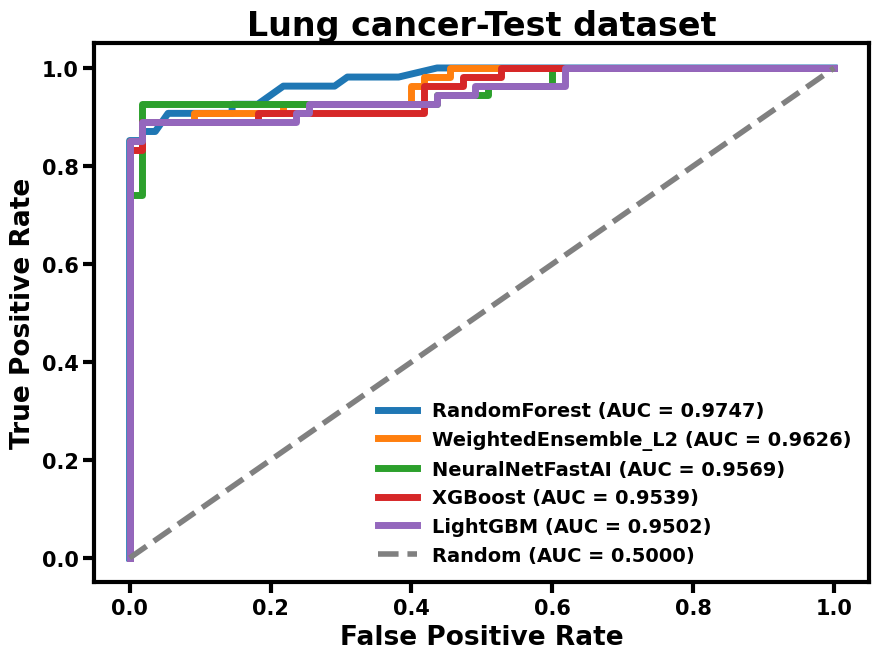

In [60]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split

# 加载模型并绘制 ROC 曲线
def plot_roc_curves_ReliefF(data, model_dir):
    # 加载整个 predictor 对象
    ReliefF_predictor = TabularPredictor.load(model_dir)

    # 定义你想加载的模型名称
    models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']
    
    # 用于存储每个模型和对应的 AUC 值
    auc_scores = []
    
    plt.figure(figsize=(10, 7))

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    train_data, test_data = train_test_split(
        data, test_size=0.2, random_state=42, stratify=data['class']
    )

    y_true = test_data['class']  # 真实标签
    plot_data = []
    
    for model_name in models:
        # 加载每个模型
        model = ReliefF_predictor._trainer.load_model(model_name)

        # 获取模型的预测概率
        y_prob = model.predict_proba(test_data)  # 获取每个样本的预测概率（正类的概率）

        # 计算 ROC 曲线的数据
        fpr, tpr, thresholds = roc_curve(y_true, y_prob)
        roc_auc = auc(fpr, tpr)

        # 将模型和 AUC 值存储到列表中
        auc_scores.append((model_name, roc_auc))

        # 绘制 ROC 曲线
        clean_name = model_name.replace('_BAG_L1', '').replace('_L1', '')
        plot_data.append((roc_auc, fpr, tpr, clean_name))

    plot_data.append((0.5, [0, 1], [0, 1], 'Random'))

    # 按 AUC 值降序排列
    plot_data.sort(reverse=True, key=lambda x: x[0])

    for roc_auc, fpr, tpr, label in plot_data:
        if label.lower() == 'random':
            plt.plot(fpr, tpr, lw=4, linestyle='--', color='gray', label=f'{label} (AUC = {roc_auc:.4f})')
        else:
            plt.plot(fpr, tpr, lw=5, label=f'{label} (AUC = {roc_auc:.4f})')


    # 配置图表
    plt.xlabel('False Positive Rate', fontweight='bold', fontsize=19)
    plt.ylabel('True Positive Rate', fontweight='bold', fontsize=19)
    plt.title('Lung cancer-Test dataset', fontweight='bold', fontsize=24)

    ax = plt.gca()  # 获取当前坐标轴
    for spine in ax.spines.values():
        spine.set_linewidth(3)
    ax.tick_params(axis='both', width=3, length=8)
    for tick_label in ax.get_xticklabels() + ax.get_yticklabels():
        tick_label.set_fontsize(15)
        tick_label.set_fontweight('bold')

    plt.legend(loc='lower right', frameon=False, prop={'family': 'sans-serif', 'size': 14, 'weight': 'bold'})

    plt.savefig(f"{model_dir}", dpi=300)
    plt.show()

model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Lung cancer/ReliefF'
data = ReliefFdata 
plot_roc_curves_ReliefF(data, model_dir)


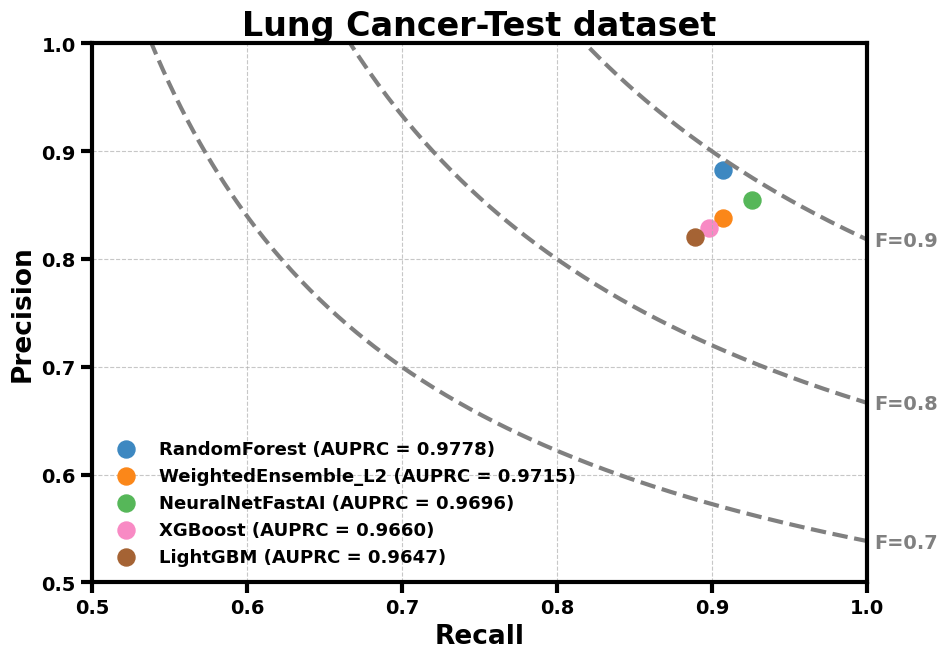

In [58]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split
import pandas as pd

def plot_pr_curves(data, model_dir):
    predictor = TabularPredictor.load(model_dir)
    models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']
    prc_scores = []

    plt.figure(figsize=(10, 7))

    # 分层采样
    train_data, test_data = train_test_split(
        data, test_size=0.2, random_state=42, stratify=data['class']
    )
    y_true = test_data['class']

    for model_name in models:
        model = predictor._trainer.load_model(model_name)
        y_prob = model.predict_proba(test_data)

        precision, recall, _ = precision_recall_curve(y_true, y_prob)
        auprc = average_precision_score(y_true, y_prob)

        prc_scores.append((model_name, np.median(precision), np.median(recall), auprc))

    model_display_names = {
    'XGBoost_BAG_L1': 'XGBoost',
    'RandomForest_BAG_L1': 'RandomForest',
    'LightGBM_BAG_L1': 'LightGBM',
    'NeuralNetFastAI_BAG_L1': 'NeuralNetFastAI'
    }

    # 绘制散点
    colors = ['#3d88c1', '#fb8719', '#56b759', '#f88ac4', '#a56334']
    for idx, (model_name, prec, rec, auprc) in enumerate(sorted(prc_scores, key=lambda x: x[3], reverse=True)):
        label_name = model_display_names.get(model_name, model_name)
        plt.scatter(rec, prec, s=150, label=f"{label_name} (AUPRC = {auprc:.4f})", color=colors[idx])

    # 绘制 F1 等值线
    f_scores = [0.7, 0.8, 0.9]
    x = np.linspace(0.01, 1, 500)
    for f_score in f_scores:
        y = (f_score * x) / (2 * x - f_score)
        y[(2 * x - f_score) <= 0] = np.nan  # 避免无定义区域
        plt.plot(x, y, color='gray', linestyle='--', linewidth=3)
        
        valid_idx = np.where(np.isfinite(y))[0]
        if valid_idx.size > 0:
            label_x = x[valid_idx[-1]]  # 取最后一个有效点
            label_y = y[valid_idx[-1]]  # 取最后一个有效点对应的y值

            # 向右和向上偏移标签，以避免和曲线重叠
            plt.text(label_x + 0.005, label_y - 0.01, f"F={f_score}", fontsize=14, fontweight='bold', color='gray', verticalalignment='bottom')
    
    # 配置美化
    plt.xlabel('Recall', fontsize=19, fontweight='bold')
    plt.ylabel('Precision', fontsize=19, fontweight='bold')
    plt.title('Lung Cancer-Test dataset', fontsize=24, fontweight='bold')
    plt.grid(True, linestyle='--', alpha=0.7)

    # 图例放到外面
    # plt.legend(fontsize=10, loc='center left', bbox_to_anchor=(1.05, 0.5), frameon=False)
    plt.xlim(0.5, 1.0)
    plt.ylim(0.5, 1.0)

    ax = plt.gca()  # 获取当前坐标轴
    for spine in ax.spines.values():
        spine.set_linewidth(3)
    ax.tick_params(axis='both', width=3, length=8)
    for tick_label in ax.get_xticklabels() + ax.get_yticklabels():
        tick_label.set_fontsize(14)
        tick_label.set_fontweight('bold')

    plt.legend(loc='lower left', frameon=False, prop={'family': 'sans-serif', 'size': 13, 'weight': 'bold'})
    plt.savefig(f"{model_dir}_PR.png", dpi=300)
    plt.show()

model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Lung cancer/ReliefF'
data = ReliefFdata 
plot_pr_curves(data, model_dir)

In [5]:
import pandas as pd
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, recall_score, precision_score
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split

# 重新加载模型和数据
model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Lung cancer/ReliefF'
predictor = TabularPredictor.load(model_dir)
data = ReliefFdata

# 模型名称列表
models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']

# 数据划分
train_data, test_data = train_test_split(data, test_size=0.2, stratify=data['class'], random_state=42)

# 用于保存结果
results = []

# 遍历每个模型并计算各项指标
for model_name in models:
    model = predictor._trainer.load_model(model_name)
    
    for set_name, df in [('Train', train_data), ('Test', test_data)]:
        y_true = df['class']
        y_proba = model.predict_proba(df)
        if isinstance(y_proba, pd.DataFrame):
            y_score = y_proba.iloc[:, 1]
        else:
            y_score = y_proba
        y_pred = (y_score >= 0.5).astype(int)

        results.append({
            'Model': model_name,
            'Set': set_name,
            'AUC': roc_auc_score(y_true, y_score),
            'Accuracy': accuracy_score(y_true, y_pred),
            'F1': f1_score(y_true, y_pred),
            'Recall': recall_score(y_true, y_pred),
            'Precision': precision_score(y_true, y_pred)
        })

# 转换为 DataFrame 展示
results_df = pd.DataFrame(results)
# 按 Test AUC 排序，仅保留 Test 行并根据 AUC 降序排列后提取顺序索引
test_auc_order = results_df[results_df['Set'] == 'Test'].sort_values(by='AUC', ascending=False)['Model']

# 按上述顺序重新排列整个结果 DataFrame（Validation 和 Test 行都保持）
results_df['Model'] = pd.Categorical(results_df['Model'], categories=test_auc_order, ordered=True)
results_df = results_df.sort_values(by=['Model', 'Set']).reset_index(drop=True)
results_df

,Model,Set,AUC,Accuracy,F1,Recall,Precision
0,RandomForest_BAG_L1,Test,0.974747,0.926606,0.920000,0.851852,1.000000
1,RandomForest_BAG_L1,Train,1.000000,1.000000,1.000000,1.000000,1.000000
2,WeightedEnsemble_L2,Test,0.962626,0.917431,0.910891,0.851852,0.978723
3,WeightedEnsemble_L2,Train,1.000000,1.000000,1.000000,1.000000,1.000000
4,NeuralNetFastAI_BAG_L1,Test,0.956902,0.908257,0.900000,0.833333,0.978261
5,NeuralNetFastAI_BAG_L1,Train,0.998901,0.983908,0.983982,0.986239,0.981735
6,XGBoost_BAG_L1,Test,0.953872,0.926606,0.923077,0.888889,0.960000
7,XGBoost_BAG_L1,Train,1.000000,1.000000,1.000000,1.000000,1.000000
8,LightGBM_BAG_L1,Test,0.950168,0.935780,0.932039,0.888889,0.979592
9,LightGBM_BAG_L1,Train,1.000000,1.000000,1.000000,1.000000,1.000000


### Binomial

In [12]:
# 加载数据集
file_path = '../Binomial/Lung_sample_BinomialSorted_selected42.csv'
Binomialdata = pd.read_csv(file_path)

# 数据存储目录
output_dir = "../all_biomaker_detection/"
os.makedirs(output_dir, exist_ok=True)

In [ ]:
# 准备训练和测试集函数
def prepare_train_test_Binomial(data, cancer_type, output_dir):

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    sgkf = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    train_idx, test_idx = next(
        sgkf.split(
            data,
            y=data["class"],
            groups=data["SampleID"]
        )
    )

    train_data = data.iloc[train_idx]
    test_data = data.iloc[test_idx]

    train_data = train_data.drop(columns=["SampleID"])
    test_data = test_data.drop(columns=["SampleID"])

    # 设置模型保存路径
    model_path = os.path.join(output_dir, f"Model_{cancer_type}/Binomial/")
    os.makedirs(model_path, exist_ok=True)

    # 训练 AutoGluon 模型
    predictor = TabularPredictor(label='class', eval_metric='roc_auc', path=model_path).fit(
        train_data=train_data,
        presets='best_quality',
        hyperparameters={'XGB': {}, 'RF': {'criterion': 'gini'}, 'GBM': {}, 'FASTAI': {}, 'ENS_WEIGHTED': {}},
        # num_bag_folds=5
    )

    # predictor=TabularPredictor.load(f".\pancancer_detection\Model_{cancer_type}/")

    # 查看模型排行榜
    leaderboard = predictor.leaderboard(test_data, extra_metrics=['accuracy', 'balanced_accuracy', 'mcc', 'f1', 'precision', 'recall', 'roc_auc'])
    return leaderboard

In [21]:
Lung_leaderboard_Binomial = prepare_train_test_Binomial(Binomialdata, "Lung cancer", output_dir)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.1.1
Python Version:     3.12.9
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #53~22.04.1-Ubuntu SMP PREEMPT_DYNAMIC Wed Jan 15 19:18:46 UTC 2
CPU Count:          48
Memory Avail:       186.58 GB / 251.54 GB (74.2%)
Disk Space Avail:   8943.95 GB / 14784.53 GB (60.5%)
Presets specified: ['best_quality']
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1
DyStack is enabled (dynamic_stacking=True). AutoGluon will try to determine whether the input data is affected by stacked overfitting and enable or disable stacking as a consequence.
	This is used to identify the optimal `num_stack_levels` value. Copies of AutoGluon will be fit on subsets of the data. Then holdout validation data is u

In [22]:
Lung_leaderboard_Binomial.to_csv("Lung_leaderboard_Binomial.csv", index=False)
Lung_leaderboard_Binomial

,model,score_test,accuracy,balanced_accuracy,mcc,f1,precision,recall,roc_auc,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,RandomForest_BAG_L1,0.925926,0.880734,0.880135,0.767540,0.871287,0.936170,0.814815,0.925926,0.982243,roc_auc,0.043398,0.108776,1.174175,0.043398,0.108776,1.174175,1,True,2
1,WeightedEnsemble_L3,0.925926,0.880734,0.880135,0.767540,0.871287,0.936170,0.814815,0.925926,0.984188,roc_auc,1.722816,0.344109,9.947517,0.001912,0.000485,0.050438,3,True,11
2,WeightedEnsemble_L2,0.923906,0.880734,0.880135,0.767540,0.871287,0.936170,0.814815,0.923906,0.983723,roc_auc,0.290984,0.132642,1.882429,0.001686,0.000441,0.026346,2,True,5
3,WeightedEnsemble_BAG_L2,0.923906,0.880734,0.880135,0.767540,0.871287,0.936170,0.814815,0.923906,0.983575,roc_auc,1.282270,0.310241,8.695397,0.005921,0.006304,0.139835,2,True,10
4,LightGBM_BAG_L1,0.921549,0.871560,0.871380,0.743512,0.867925,0.884615,0.851852,0.921549,0.975056,roc_auc,0.150205,0.007756,0.631625,0.150205,0.007756,0.631625,1,True,1
5,XGBoost_BAG_L1,0.919192,0.862385,0.861953,0.727590,0.854369,0.897959,0.814815,0.919192,0.974570,roc_auc,0.245899,0.023426,0.681908,0.245899,0.023426,0.681908,1,True,4
6,LightGBM_BAG_L2,0.913805,0.889908,0.889226,0.788062,0.880000,0.956522,0.814815,0.913805,0.979516,roc_auc,1.425434,0.311968,9.126765,0.149086,0.008030,0.571203,2,True,6
7,NeuralNetFastAI_BAG_L2,0.913131,0.844037,0.843434,0.693437,0.831683,0.893617,0.777778,0.913131,0.977952,roc_auc,1.888849,0.562429,14.147404,0.612501,0.258491,5.591842,2,True,8
8,RandomForest_BAG_L2,0.912121,0.880734,0.880135,0.767540,0.871287,0.936170,0.814815,0.912121,0.978650,roc_auc,1.325052,0.407329,9.767592,0.048703,0.103391,1.212029,2,True,7
9,XGBoost_BAG_L2,0.903367,0.871560,0.870707,0.755538,0.857143,0.954545,0.777778,0.903367,0.979812,roc_auc,1.565897,0.329290,9.186042,0.289549,0.025352,0.630480,2,True,9


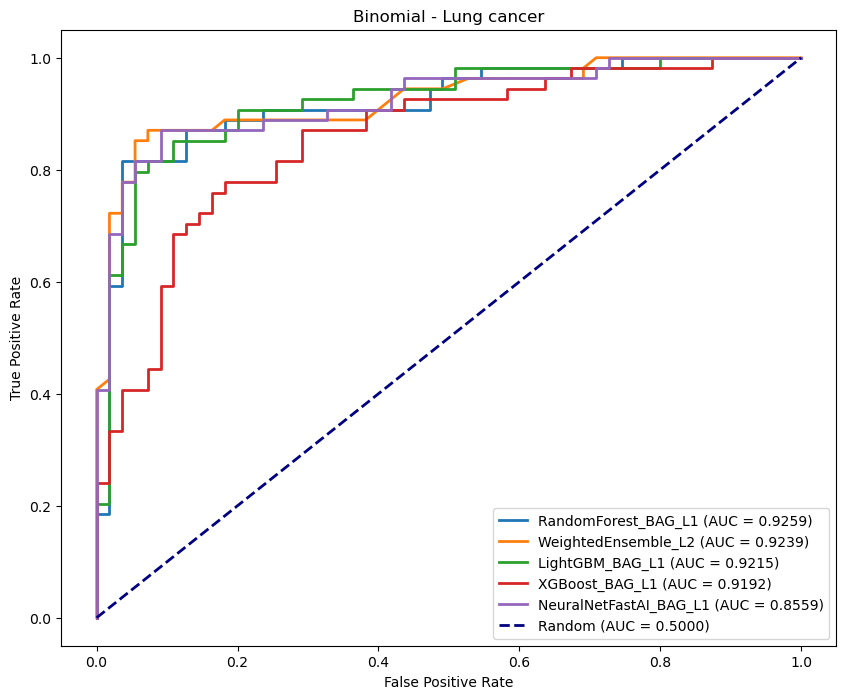

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split

# 加载模型并绘制 ROC 曲线
def plot_roc_curves_Binomial(data, model_dir):
    # 加载整个 predictor 对象
    Binomial_predictor = TabularPredictor.load(model_dir)

    # 定义你想加载的模型名称
    models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']
    
    # 用于存储每个模型和对应的 AUC 值
    auc_scores = []
    
    plt.figure(figsize=(10, 8))

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    train_data, test_data = train_test_split(
        data, test_size=0.2, random_state=42, stratify=data['class']
    )

    y_true = test_data['class']  # 真实标签
    
    for model_name in models:
        # 加载每个模型
        model = Binomial_predictor._trainer.load_model(model_name)

        # 获取模型的预测概率
        y_prob = model.predict_proba(test_data)  # 获取每个样本的预测概率（正类的概率）

        # 计算 ROC 曲线的数据
        fpr, tpr, thresholds = roc_curve(y_true, y_prob)
        roc_auc = auc(fpr, tpr)

        # 将模型和 AUC 值存储到列表中
        auc_scores.append((model_name, roc_auc))

        # 绘制 ROC 曲线
        plt.plot(fpr, tpr, lw=2, label=f'{model_name} (AUC = {roc_auc:.4f})')

    # 按照 AUC 值从大到小排序
    auc_scores.append(('Random', 0.5))
    auc_scores.sort(key=lambda x: x[1], reverse=True)

    # 绘制随机猜测线
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label="Random (AUC = 0.5)")

    # 配置图表
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Binomial - Lung cancer')

    # 使用排序后的 AUC 值生成图例
    sorted_labels = [f'{model_name} (AUC = {roc_auc:.4f})' for model_name, roc_auc in auc_scores]
    plt.legend(sorted_labels, loc='lower right')

    plt.savefig(f"{model_dir}", dpi=300)
    plt.show()

model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Lung cancer/Binomial'
data = Binomialdata 
plot_roc_curves_Binomial(data, model_dir)


### biomaker分析

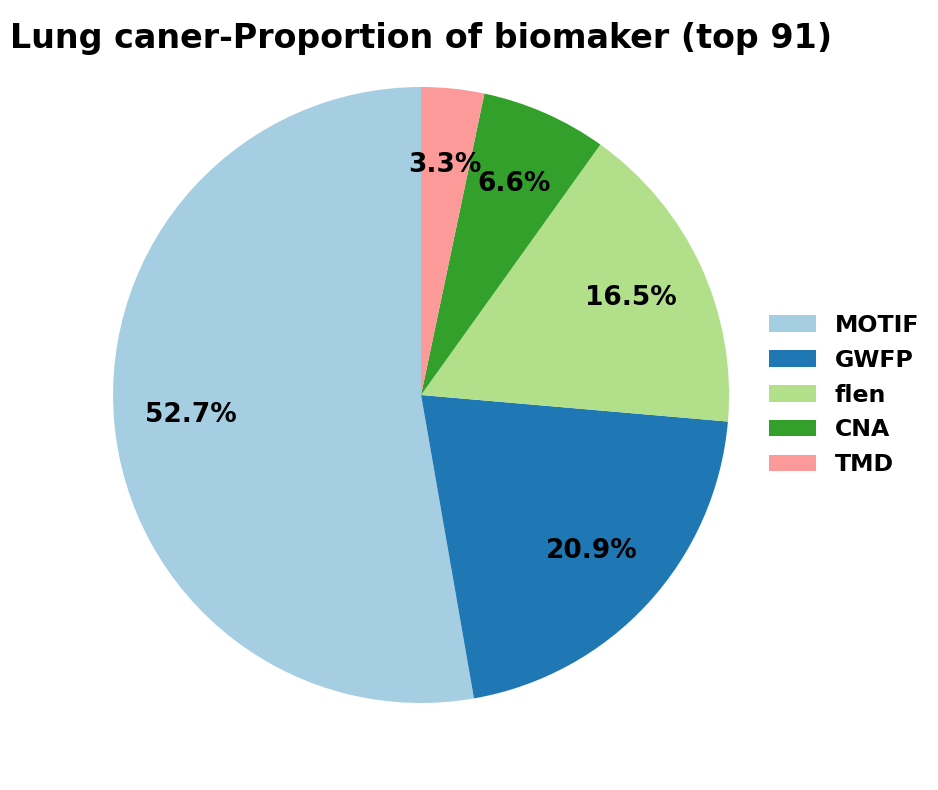

In [57]:
import pandas as pd
import matplotlib.pyplot as plt

file_path = '/home/xwluo/cfDNA/elife/ReliefF/Lung_feature_importance.csv'
df = pd.read_csv(file_path, header=None, names=['Index', 'Marker', 'Value'])
df = df.head(91)

# 判断每个Marker的类型，并将其分类
def classify_marker(marker):
    if "GWMD" in marker:
        return "GWMD"
    elif "TMD" in marker:
        return "TMD"
    elif "GWFP" in marker:
        return "GWFP"
    elif "flen" in marker:
        return "flen"
    elif "MOTIF" in marker:
        return "MOTIF"
    elif "CNA" in marker:
        return "CNA"
    else:
        return "Other"

# 将每个Marker进行分类
df['Type'] = df['Marker'].apply(classify_marker)

# 统计各类型的数量
type_counts = df['Type'].value_counts()

# 设置颜色
colors = plt.cm.Paired(range(len(type_counts)))

# 创建画布和饼图
fig, ax = plt.subplots(figsize=(10, 8))

wedges, texts, autotexts = ax.pie(
    type_counts,
    labels=None,  # 不显示板块外的分类名
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    pctdistance=0.75,
    textprops={'fontsize': 19, 'weight': 'bold'}

)

# 添加图例靠近图形，去掉边框
plt.legend(
    type_counts.index,
    bbox_to_anchor=(0.93, 0.5),  # 靠近饼图
    loc='center left',
    frameon=False,
    borderaxespad=0.3, 
    prop={'family': 'sans-serif', 'size': 17, 'weight': 'bold'}
)

# 标题
plt.title('Lung caner-Proportion of biomaker (top 91)', fontsize=24, fontweight='bold', y=0.94)

# 保持圆形 + 紧凑布局
# plt.axis('equal')
plt.tight_layout()
plt.savefig("Lung-ReliefF-Proportion of Biomaker_Optimized.png", dpi=300)
plt.show()


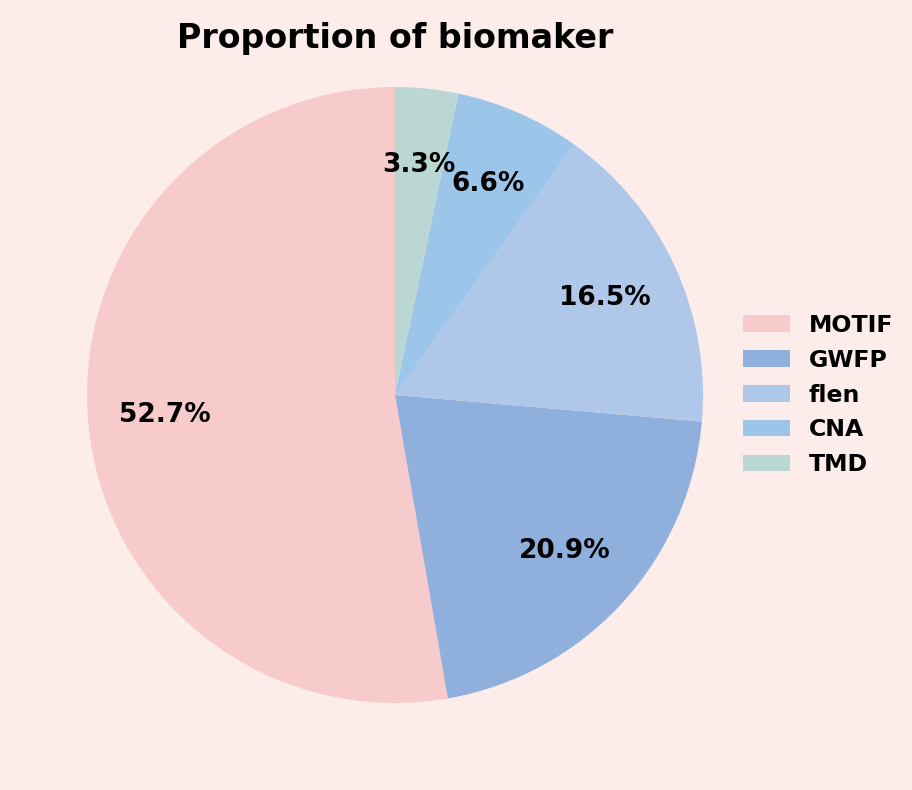

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

file_path = '/home/xwluo/cfDNA/elife/ReliefF/Lung_feature_importance.csv'
df = pd.read_csv(file_path, header=None, names=['Index', 'Marker', 'Value'])
df = df.head(91)

# 判断每个Marker的类型，并将其分类
def classify_marker(marker):
    if "GWMD" in marker:
        return "GWMD"
    elif "TMD" in marker:
        return "TMD"
    elif "GWFP" in marker:
        return "GWFP"
    elif "flen" in marker:
        return "flen"
    elif "MOTIF" in marker:
        return "MOTIF"
    elif "CNA" in marker:
        return "CNA"
    else:
        return "Other"

# 将每个Marker进行分类
df['Type'] = df['Marker'].apply(classify_marker)

# 统计各类型的数量
type_counts = df['Type'].value_counts()

# 设置颜色
colors = plt.cm.Paired(range(len(type_counts)))

# 背景色
bg_color = '#FCEDEB'

# 小配图的低饱和冷色调配色，并按类别稳定映射
color_map = {
    'TMD':'#bad7d3',
    'GWFP': '#8fb0dc',
    'flen':  '#afc7e9',
    'MOTIF':'#f7cbcb',
    'CNA':  '#9bc5e9',

}
# 根据统计顺序取色，保证图例顺序与颜色一致
colors = [color_map.get(t, '#9DC7BE') for t in type_counts.index]


# 创建画布和饼图
# fig, ax = plt.subplots(figsize=(10, 8))
fig, ax = plt.subplots(figsize=(10, 8), facecolor=bg_color)
ax.set_facecolor(bg_color)

wedges, texts, autotexts = ax.pie(
    type_counts,
    labels=None,  # 不显示板块外的分类名
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    pctdistance=0.75,
    textprops={'fontsize': 19, 'weight': 'bold'}

)

# 添加图例靠近图形，去掉边框
plt.legend(
    type_counts.index,
    bbox_to_anchor=(0.93, 0.5),  # 靠近饼图
    loc='center left',
    frameon=False,
    borderaxespad=0.3, 
    prop={'family': 'sans-serif', 'size': 17, 'weight': 'bold'}
)

# 标题
plt.title('Proportion of biomaker', fontsize=24, fontweight='bold', y=0.94)

# 保持圆形 + 紧凑布局
# plt.axis('equal')
plt.tight_layout()
plt.savefig("Proportion of Biomaker_Optimized.png",
            dpi=300, facecolor=fig.get_facecolor())
plt.show()
